In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("BankChurnersRAW.csv", encoding="cp1251", sep=";")

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CLIENTNUM               10127 non-null  int64  
 1   Churn                   10127 non-null  int64  
 2   Age                     10127 non-null  int64  
 3   Gender                  10127 non-null  str    
 4   Dependents              10127 non-null  int64  
 5   EducationLevel          10127 non-null  str    
 6   MaritalStatus           10127 non-null  str    
 7   YearIncome              9142 non-null   float64
 8   Purpose                 10127 non-null  str    
 9   Card_Category           10127 non-null  str    
 10  Months                  10127 non-null  int64  
 11  TotalRelationshipCount  10127 non-null  int64  
 12  MonthsInactive12        10127 non-null  int64  
 13  ContactsCount12         10127 non-null  int64  
 14  CreditLimit             10127 non-null  int64  
 

In [3]:
df.describe()

,CLIENTNUM,Churn,Age,Dependents,YearIncome,Months,TotalRelationshipCount,MonthsInactive12,ContactsCount12,CreditLimit,TotalAmtChngQ4Q1,TotalTransAmt,TotalCtChngQ4Q1,AvgUtilizationRatio
count,1.012700e+04,10127.000000,10127.000000,10127.000000,9.142000e+03,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,0.160660,46.325960,2.364767,1.665495e+05,35.928409,3.812580,2.341167,2.455317,86319.536980,0.759941,4404.086304,0.712222,0.274894
std,3.690378e+07,0.367235,8.016814,1.516730,9.842446e+04,7.986416,1.554408,1.010622,1.106225,90887.766502,0.219207,3397.129254,0.238086,0.275691
min,7.080821e+08,0.000000,26.000000,-1.000000,2.169510e+04,13.000000,1.000000,0.000000,0.000000,14383.000000,0.000000,510.000000,0.000000,0.000000
25%,7.130368e+08,0.000000,41.000000,1.000000,1.030791e+05,31.000000,3.000000,2.000000,2.000000,25550.000000,0.631000,2155.500000,0.582000,0.023000
50%,7.179264e+08,0.000000,46.000000,2.000000,1.447983e+05,36.000000,4.000000,2.000000,2.000000,45490.000000,0.736000,3899.000000,0.702000,0.176000
75%,7.731435e+08,0.000000,52.000000,3.000000,2.024765e+05,40.000000,5.000000,3.000000,3.000000,110675.000000,0.859000,4741.000000,0.818000,0.503000
max,8.283431e+08,1.000000,73.000000,30.000000,1.726276e+06,56.000000,6.000000,6.000000,6.000000,345160.000000,3.397000,18484.000000,3.714000,0.999000


In [4]:
df.describe(include=["bool", "object"])

/tmp/ipykernel_66508/1308147894.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["bool", "object"])


,Gender,EducationLevel,MaritalStatus,Purpose,Card_Category
count,10127,10127,10127,10127,10127
unique,4,15,5,38,4
top,F,среднее,женат / замужем,свадьба,Blue
freq,5357,6446,5815,383,9436


In [5]:
df["Dependents"].value_counts(normalize=True, sort=True)

Dependents
 3     0.268984
 2     0.261578
 1     0.181298
 4     0.155327
 0     0.089168
 5     0.041868
-1     0.000987
 30    0.000790
Name: proportion, dtype: float64

In [6]:
df[(df["Gender"] == "F")].sort_values(by="YearIncome", ascending=True).head()

,CLIENTNUM,Churn,Age,Gender,Dependents,EducationLevel,MaritalStatus,YearIncome,Purpose,Card_Category,Months,TotalRelationshipCount,MonthsInactive12,ContactsCount12,CreditLimit,TotalAmtChngQ4Q1,TotalTransAmt,TotalCtChngQ4Q1,AvgUtilizationRatio
2698,754671558,0,50,F,3,среднее,женат / замужем,29426.69255,недвижимость,Blue,43,6,1,4,29990,0.611,2073,0.714,0.653
544,709103358,0,39,F,2,среднее,женат / замужем,31433.99524,операции с жильем,Blue,36,6,3,3,94760,0.605,1128,0.929,0.000
6200,752766783,0,43,F,4,среднее,гражданский брак,31586.48665,сделка с подержанным автомобилем,Blue,36,5,2,2,115360,0.549,4106,0.723,0.180
2669,713902983,0,42,F,3,СРЕДНЕЕ,женат / замужем,31815.93745,операции с недвижимостью,Blue,36,4,3,1,16760,0.522,4381,0.571,0.819
7990,712853358,1,39,F,3,среднее,женат / замужем,31951.16478,образование,Blue,36,2,3,2,18170,0.583,2216,0.833,0.000


In [7]:
df[(df["Gender"] == "F")].sort_values(by=["Dependents", "YearIncome"]).min()

CLIENTNUM                             708082083
Churn                                         0
Age                                          26
Gender                                        F
Dependents                                   -1
EducationLevel                           ВЫСШЕЕ
MaritalStatus             Не женат / не замужем
YearIncome                          29426.69255
Purpose                              автомобили
Card_Category                              Blue
Months                                       13
TotalRelationshipCount                        1
MonthsInactive12                              0
ContactsCount12                               0
CreditLimit                               14383
TotalAmtChngQ4Q1                            0.0
TotalTransAmt                               510
TotalCtChngQ4Q1                             0.0
AvgUtilizationRatio                         0.0
dtype: object

In [8]:
df[(df["Gender"] == "M")].sort_values(
    by=["Dependents", "YearIncome"], ascending=[True, True]
).min()

CLIENTNUM                             708083283
Churn                                         0
Age                                          26
Gender                                        M
Dependents                                   -1
EducationLevel                           ВЫСШЕЕ
MaritalStatus             Не женат / не замужем
YearIncome                          21695.10179
Purpose                              автомобили
Card_Category                              Blue
Months                                       13
TotalRelationshipCount                        1
MonthsInactive12                              0
ContactsCount12                               0
CreditLimit                               14383
TotalAmtChngQ4Q1                            0.0
TotalTransAmt                               530
TotalCtChngQ4Q1                             0.0
AvgUtilizationRatio                         0.0
dtype: object

Homework

In [9]:
df["Card_Category"].value_counts()

Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

In [10]:
df.sort_values(by="CreditLimit", ascending=False)

,CLIENTNUM,Churn,Age,Gender,Dependents,EducationLevel,MaritalStatus,YearIncome,Purpose,Card_Category,Months,TotalRelationshipCount,MonthsInactive12,ContactsCount12,CreditLimit,TotalAmtChngQ4Q1,TotalTransAmt,TotalCtChngQ4Q1,AvgUtilizationRatio
45,712661433,0,49,M,4,среднее,женат / замужем,181337.45120,покупка своего жилья,Blue,30,3,2,3,345160,1.621,1444,1.333,0.000
6408,820657083,0,53,M,4,среднее,Не женат / не замужем,89165.64069,получение высшего образования,Silver,48,5,1,2,345160,0.804,3819,0.600,0.023
9474,754443033,1,50,M,1,среднее,в разводе,209743.11920,сделка с автомобилем,Silver,43,6,3,3,345160,0.807,9045,1.000,0.013
9513,713390433,1,44,M,3,среднее,женат / замужем,132059.48390,приобретение автомобиля,Gold,29,2,3,2,345160,0.579,6782,0.763,0.073
9456,789289383,0,42,M,3,среднее,Не женат / не замужем,NaN,свадьба,Silver,31,2,2,3,345160,0.900,14626,0.644,0.061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6976,712579983,0,40,F,2,среднее,женат / замужем,154929.72380,операции со своей недвижимостью,Blue,30,5,2,3,14383,0.542,2258,0.788,0.000
7252,808669083,0,52,F,1,среднее,женат / замужем,162603.57350,операции с коммерческой недвижимостью,Blue,47,3,1,3,14383,0.775,5015,0.789,0.000
7248,789271533,0,51,F,1,неоконченное высшее,женат / замужем,224330.91220,на покупку своего автомобиля,Blue,40,5,3,2,14383,0.615,4653,0.897,0.631
7247,770180808,0,37,F,4,среднее,женат / замужем,168756.26330,автомобили,Blue,31,3,3,2,14383,0.919,5001,0.625,0.000


In [11]:
df["CreditLimit"].mean()

np.float64(86319.53698034956)

In [12]:
df[df["Churn"] == 1]["CreditLimit"].mean()

np.float64(81360.39459127228)

In [13]:
df.groupby("Churn")["CreditLimit"].mean()

Churn
0    87268.775176
1    81360.394591
Name: CreditLimit, dtype: float64

In [14]:
df[(df["Churn"] == 1) & (df["Dependents"] > 2)]["AvgUtilizationRatio"].max()

np.float64(0.999)

In [15]:
df.groupby("Card_Category")["CreditLimit"].mean()

Card_Category
Blue         73637.800021
Gold        284163.706897
Platinum    302834.500000
Silver      252778.360360
Name: CreditLimit, dtype: float64

In [16]:
df.groupby("Card_Category")["CreditLimit"].max()

Card_Category
Blue        345160
Gold        345160
Platinum    345160
Silver      345160
Name: CreditLimit, dtype: int64

In [17]:
df.groupby("Card_Category")["CreditLimit"].min()

Card_Category
Blue         14383
Gold         37350
Platinum    159870
Silver       37350
Name: CreditLimit, dtype: int64

In [18]:
df.groupby("Card_Category")["CreditLimit"].median()

Card_Category
Blue         41050.0
Gold        345160.0
Platinum    345160.0
Silver      298080.0
Name: CreditLimit, dtype: float64

In [19]:
df.groupby("Card_Category")["CreditLimit"].agg(["max", "min", "mean", "median"])

,max,min,mean,median
Card_Category,,,,
Blue,345160,14383,73637.800021,41050.0
Gold,345160,37350,284163.706897,345160.0
Platinum,345160,159870,302834.500000,345160.0
Silver,345160,37350,252778.360360,298080.0


In [20]:
df.columns = ['id', 'churn', 'age', 'gender', 'dependents',
       'edu_level', 'marital_status', 'year_income', 'purpose',
       'card_category', 'month_client', 'total_products',
       'm_inactive_12', 'contacts_12', 'credit_limit',
       'total_amt_chng_Q4Q1', 'total_transactions', 'total_ct_chng_Q4Q1',
       'avg_utilization_ratio']

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     10127 non-null  int64  
 1   churn                  10127 non-null  int64  
 2   age                    10127 non-null  int64  
 3   gender                 10127 non-null  str    
 4   dependents             10127 non-null  int64  
 5   edu_level              10127 non-null  str    
 6   marital_status         10127 non-null  str    
 7   year_income            9142 non-null   float64
 8   purpose                10127 non-null  str    
 9   card_category          10127 non-null  str    
 10  month_client           10127 non-null  int64  
 11  total_products         10127 non-null  int64  
 12  m_inactive_12          10127 non-null  int64  
 13  contacts_12            10127 non-null  int64  
 14  credit_limit           10127 non-null  int64  
 15  total_amt_chn

In [21]:
df['purpose'].str.contains('свад')

0         True
1         True
2        False
3        False
4         True
         ...  
10122     True
10123    False
10124    False
10125    False
10126    False
Name: purpose, Length: 10127, dtype: bool

In [22]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
10122    False
10123    False
10124    False
10125    False
10126    False
Length: 10127, dtype: bool

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df['edu_level'].value_counts()

edu_level
среднее                6446
высшее                 2207
СРЕДНЕЕ                 360
Среднее                 341
неоконченное высшее     316
начальное               140
Высшее                  136
ВЫСШЕЕ                  129
Неоконченное высшее      22
НЕОКОНЧЕННОЕ ВЫСШЕЕ      14
НАЧАЛЬНОЕ                 7
Начальное                 6
ученая степень            1
УЧЕНАЯ СТЕПЕНЬ            1
Ученая степень            1
Name: count, dtype: int64

In [25]:
df['edu_level'] = df['edu_level'].str.lower()

df['edu_level'].value_counts()

edu_level
среднее                7147
высшее                 2472
неоконченное высшее     352
начальное               153
ученая степень            3
Name: count, dtype: int64

In [26]:
df['gender'].value_counts()

gender
F      5357
M      4768
O         1
XNA       1
Name: count, dtype: int64

In [27]:
df = df.drop(df[df['gender'] == 'O'].index).reset_index(drop = True)
df = df.drop(df[df['gender'] == 'XNA'].index).reset_index(drop = True)

df['gender'].value_counts()

gender
F    5357
M    4768
Name: count, dtype: int64

In [28]:
df['dependents'].value_counts()

dependents
 3     2724
 2     2647
 1     1836
 4     1573
 0      903
 5      424
-1       10
 30       8
Name: count, dtype: int64

In [29]:
df = df.drop(df[df['dependents'] == -1].index).reset_index(drop = True)
df = df.drop(df[df['dependents'] == 30].index).reset_index(drop =True)

df['dependents'].value_counts()

dependents
3    2724
2    2647
1    1836
4    1573
0     903
5     424
Name: count, dtype: int64

In [30]:
df['purpose'].value_counts()

purpose
свадьба                                   383
на проведение свадьбы                     377
сыграть свадьбу                           350
покупка жилья для сдачи                   321
операции с недвижимостью                  321
покупка жилья для семьи                   316
строительство жилой недвижимости          316
покупка жилья                             309
операции со своей недвижимостью           305
покупка коммерческой недвижимости         305
недвижимость                              294
покупка своего жилья                      294
строительство недвижимости                293
операции с коммерческой недвижимостью     292
ремонт жилью                              290
жилье                                     288
покупка недвижимости                      283
операции с жильем                         279
строительство собственной недвижимости    276
покупка жилой недвижимости                267
на покупку своего автомобиля              240
заняться высшим образовани

In [31]:
!pip install pymystem3

In [32]:
from pymystem3 import Mystem
from collections import Counter

m = Mystem()

In [33]:
m.lemmatize("Мы покупаем автомобиль")

['мы', ' ', 'покупать', ' ', 'автомобиль', '\n']

In [34]:
df2 = df.sample(200)
df2

,id,churn,age,gender,dependents,edu_level,marital_status,year_income,purpose,card_category,month_client,total_products,m_inactive_12,contacts_12,credit_limit,total_amt_chng_Q4Q1,total_transactions,total_ct_chng_Q4Q1,avg_utilization_ratio
9361,716947083,0,32,M,3,среднее,в разводе,109837.47410,покупка жилья для сдачи,Blue,36,2,2,1,38450,0.847,14593,0.803,0.487
4593,712817808,0,39,M,2,среднее,женат / замужем,NaN,свой автомобиль,Blue,23,5,2,1,47610,0.690,2045,1.650,0.328
4985,807426033,0,37,M,2,неоконченное высшее,вдовец / вдова,72824.95518,покупка своего жилья,Blue,32,4,1,1,28650,0.665,3462,0.906,0.410
1079,719392833,0,45,F,3,среднее,женат / замужем,94365.31202,заняться высшим образованием,Blue,38,3,3,2,24000,0.629,1311,0.417,0.672
3801,708451233,0,46,F,3,среднее,женат / замужем,179979.31040,недвижимость,Blue,36,5,3,4,50900,0.580,3707,0.440,0.324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5246,716929233,0,43,F,3,среднее,гражданский брак,87575.11371,операции с жильем,Blue,24,3,3,4,51820,0.874,5235,0.586,0.310
8327,716558283,0,30,F,0,среднее,женат / замужем,142416.35200,недвижимость,Blue,36,2,2,2,16210,0.729,5247,0.615,0.645
925,713854608,0,62,M,1,среднее,женат / замужем,148435.21080,на покупку подержанного автомобиля,Blue,36,6,3,3,95210,1.308,2444,0.400,0.175
3047,758202858,0,47,F,3,среднее,Не женат / не замужем,221779.24810,получение образования,Blue,40,4,2,4,42550,0.650,3453,0.500,0.395


In [35]:
purpose_list = []

for i in range(len(df2)):
    purpose = df2.iloc[i, 8]

    lemman = m.lemmatize(purpose)

    for j in range(len(lemman)):
        purpose_list.append(lemman[j])

In [36]:
Counter(purpose_list).most_common(10)

[(' ', 314),
 ('\n', 200),
 ('недвижимость', 61),
 ('покупка', 58),
 ('автомобиль', 45),
 ('жилье', 39),
 ('образование', 36),
 ('с', 27),
 ('свой', 23),
 ('операция', 23)]

In [37]:
def purpuse_cat(text):

    cat_list = ['жилье', 'автомобиль', 'недвижимость', 'образование', 'свадьба', 'строительство', 'ремонт']
    lemmans = m.lemmatize(text)

    for cat in cat_list:
        if cat in lemmans:
            return cat
    return 'иное'
    
    

In [38]:
df['purpose2'] = df['purpose'].apply(purpuse_cat)
df


,id,churn,age,gender,dependents,edu_level,marital_status,year_income,purpose,card_category,month_client,total_products,m_inactive_12,contacts_12,credit_limit,total_amt_chng_Q4Q1,total_transactions,total_ct_chng_Q4Q1,avg_utilization_ratio,purpose2
0,768805383,0,45,M,3,среднее,женат / замужем,277188.4448,сыграть свадьбу,Blue,39,5,1,3,126910,1.335,1144,1.625,0.061,свадьба
1,818770008,0,49,F,5,среднее,женат / замужем,162146.5421,свадьба,Blue,44,6,1,2,82560,1.541,1291,3.714,0.105,свадьба
2,713982108,0,51,M,3,высшее,гражданский брак,269423.9630,покупка жилья для семьи,Blue,36,4,1,0,34180,2.594,1887,2.333,0.000,жилье
3,769911858,0,40,F,4,высшее,гражданский брак,194744.7968,покупка жилья для сдачи,Blue,34,3,4,1,33130,1.405,1171,2.333,0.760,жилье
4,709106358,0,40,M,3,среднее,женат / замужем,228727.3482,свадьба,Blue,21,5,1,0,47160,2.175,816,2.500,0.000,свадьба
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10102,772366833,0,50,M,2,среднее,в разводе,162638.6094,сыграть свадьбу,Blue,40,3,2,3,40030,0.703,15476,0.857,0.462,свадьба
10103,710638233,1,41,M,2,высшее,женат / замужем,135448.4796,приобретение автомобиля,Blue,25,4,2,3,42770,0.804,8764,0.683,0.511,автомобиль
10104,716506083,1,44,F,1,высшее,гражданский брак,361612.7859,на покупку автомобиля,Blue,36,5,3,4,54090,0.819,10291,0.818,0.000,автомобиль
10105,717406983,1,30,M,2,высшее,женат / замужем,132546.4535,на покупку своего автомобиля,Blue,36,4,3,3,52810,0.535,8395,0.722,0.000,автомобиль


In [39]:
df = df.replace({'purpose2': {'жилье': 'недвижимость'}})
df['purpose2'].value_counts()

purpose2
недвижимость    5049
автомобиль      2016
образование     1932
свадьба         1110
Name: count, dtype: int64

In [40]:
df.isna().sum()

id                         0
churn                      0
age                        0
gender                     0
dependents                 0
edu_level                  0
marital_status             0
year_income              982
purpose                    0
card_category              0
month_client               0
total_products             0
m_inactive_12              0
contacts_12                0
credit_limit               0
total_amt_chng_Q4Q1        0
total_transactions         0
total_ct_chng_Q4Q1         0
avg_utilization_ratio      0
purpose2                   0
dtype: int64

In [41]:
df['year_income'] = df['year_income'].fillna(df['year_income'].median())

In [42]:
df.isna().sum()

id                       0
churn                    0
age                      0
gender                   0
dependents               0
edu_level                0
marital_status           0
year_income              0
purpose                  0
card_category            0
month_client             0
total_products           0
m_inactive_12            0
contacts_12              0
credit_limit             0
total_amt_chng_Q4Q1      0
total_transactions       0
total_ct_chng_Q4Q1       0
avg_utilization_ratio    0
purpose2                 0
dtype: int64

In [43]:
df['age'].min()

np.int64(26)

In [44]:
df['age'].max()

np.int64(73)

In [45]:
df.groupby('churn')['churn'].mean()

churn
0    0.0
1    1.0
Name: churn, dtype: float64

In [46]:
df.groupby('dependents')['churn'].mean()

dependents
0    0.149502
1    0.146514
2    0.157159
3    0.176579
4    0.165289
5    0.150943
Name: churn, dtype: float64

Text(0, 0.5, 'Количество клиентов')

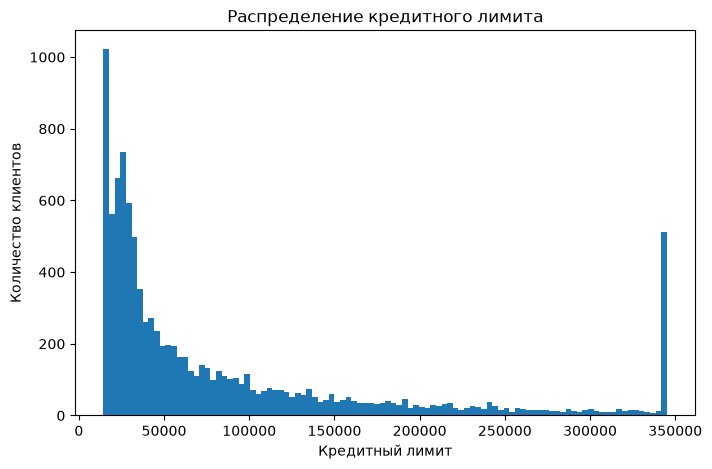

In [47]:
fig, ax = plt.subplots(figsize =(8, 5))

ax.hist(df['credit_limit'], bins = 100)
ax.set_title('Распределение кредитного лимита')
ax.set_xlabel('Кредитный лимит')
ax.set_ylabel('Количество клиентов')

In [48]:
mean_limit = df.groupby('card_category')['credit_limit'].mean().sort_values(ascending=False)
print(mean_limit)

card_category
Platinum    302834.500000
Gold        284163.706897
Silver      252778.360360
Blue         73664.005416
Name: credit_limit, dtype: float64


Text(0, 0.5, 'Лимит по картам')

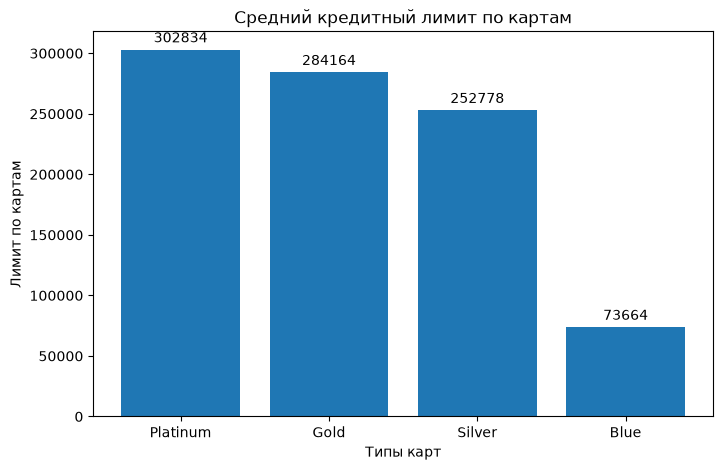

In [49]:
fig, ax = plt.subplots(figsize = (8, 5))

bars = ax.bar(mean_limit.index, mean_limit.values)
ax.bar_label(bars, fmt ='%.0f', padding = 3)
ax.set_title('Средний кредитный лимит по картам')
ax.set_xlabel('Типы карт')
ax.set_ylabel('Лимит по картам')

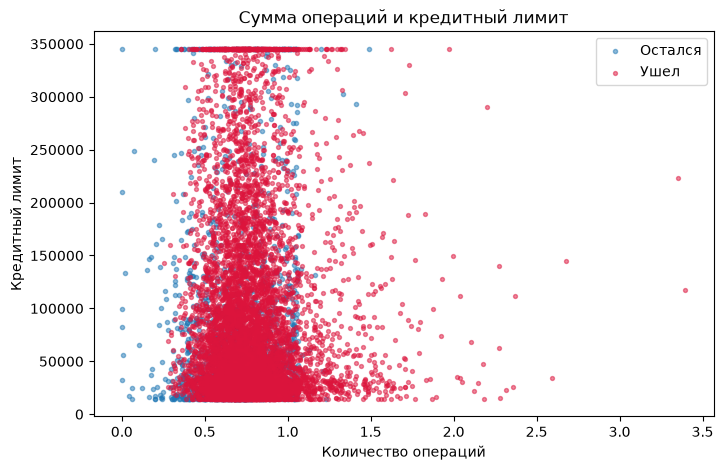

In [50]:
stay = df[df['churn'] == 1]
left = df[df['churn'] == 0]

fig, ax = plt.subplots(figsize = (8, 5))

ax.scatter(stay['total_amt_chng_Q4Q1'], stay['credit_limit'], s=9, alpha= 0.5, label = 'Остался')

ax.scatter(left['total_amt_chng_Q4Q1'], left['credit_limit'], s=8, alpha= 0.5, color = 'crimson', label = 'Ушел')
ax.set_title('Сумма операций и кредитный лимит')
ax.set_xlabel('Количество операций')
ax.set_ylabel('Кредитный лимит')
ax.legend()




Text(0, 0.5, 'Кредитный лимит')

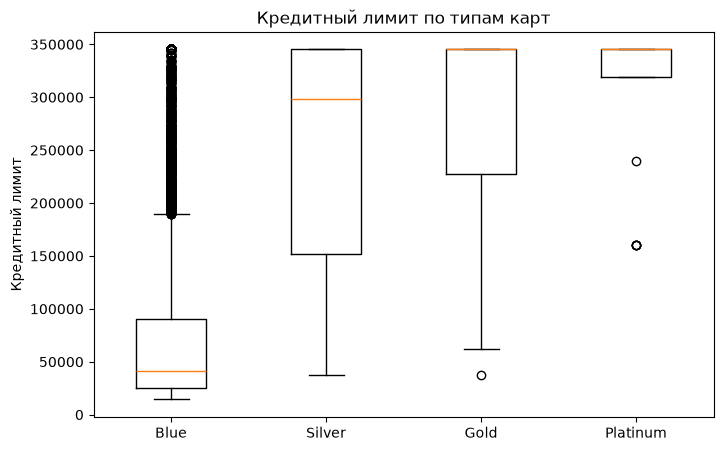

In [51]:
order = ['Blue', 'Silver', 'Gold', 'Platinum']
data = [df.loc[df['card_category'] == c, 'credit_limit'] for c in order]

fig, ax = plt.subplots(figsize = (8, 5))

ax.boxplot(data, tick_labels=order)
ax.set_title('Кредитный лимит по типам карт')
ax.set_ylabel('Кредитный лимит')

In [52]:
df['card_category'].unique()

<StringArray>
['Blue', 'Gold', 'Silver', 'Platinum']
Length: 4, dtype: str

Text(0, 0.5, 'Процент ушедших')

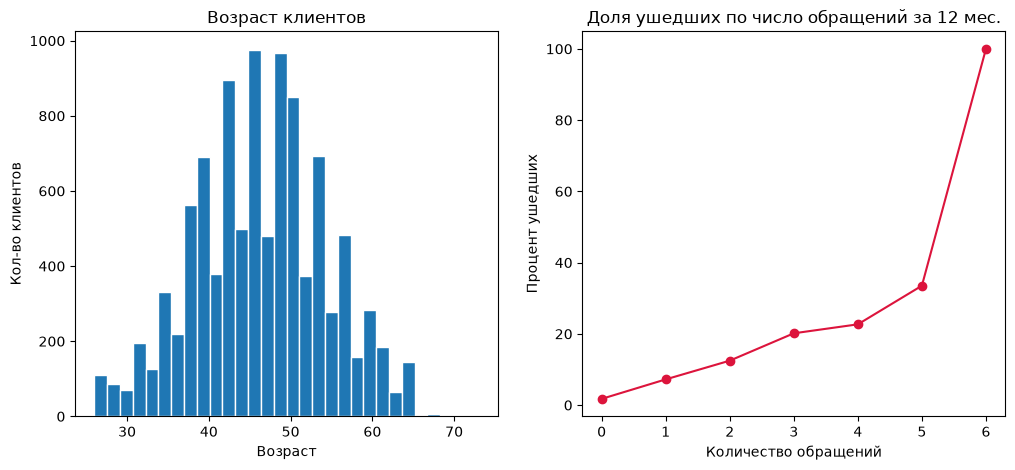

In [70]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

ax[0].hist(df['age'], bins = 30, edgecolor = 'w')
ax[0].set_title('Возраст клиентов')
ax[0].set_xlabel('Возраст')
ax[0].set_ylabel('Кол-во клиентов')

rate = df.groupby('contacts_12')['churn'].mean()*100
ax[1].plot(rate.index, rate.values, marker = 'o', color = 'crimson')
ax[1].set_title('Доля ушедших по число обращений за 12 мес.')
ax[1].set_xlabel('Количество обращений')
ax[1].set_ylabel('Процент ушедших')

**Домашнее задание**


Text(0, 0.5, 'Кол-во клиентов')

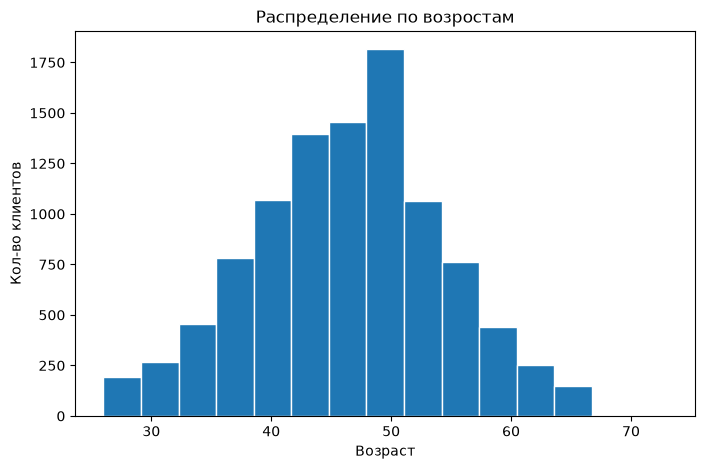

In [54]:
fig, ax = plt.subplots(figsize = (8, 5))

ax.hist(df['age'], bins=15, edgecolor = 'w')
ax.set_title('Распределение по возростам')
ax.set_xlabel('Возраст')
ax.set_ylabel('Кол-во клиентов')

*Можно заметить что больше всего клиентов в возрасте от 35 - 55, примерно. Также возраста клиентов подчиняются закону нормального распределения*

[Text(3, 0, '3'),
 Text(3, 0, '153'),
 Text(3, 0, '351'),
 Text(3, 0, '2467'),
 Text(3, 0, '7133')]

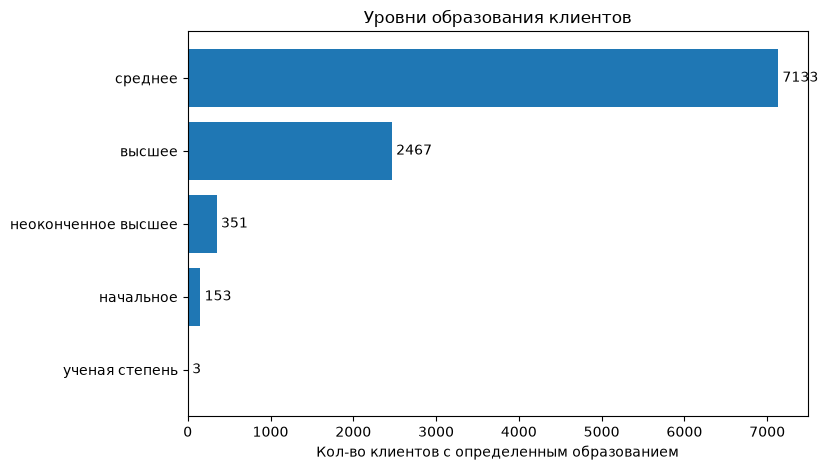

In [55]:
edu_level = df['edu_level'].value_counts(ascending=True)

fig, ax = plt.subplots(figsize = (8, 5))

bars = ax.barh(edu_level.index, edu_level.values)
ax.set_title('Уровни образования клиентов')
ax.set_xlabel('Кол-во клиентов с определенным образованием')
ax.bar_label(bars, padding= 3)


*На графике видимчто самая большая группа людей с средним и высшим образованием*

Text(0.5, 1.0, 'Доля активных клиентов и клиентов которые ушли')

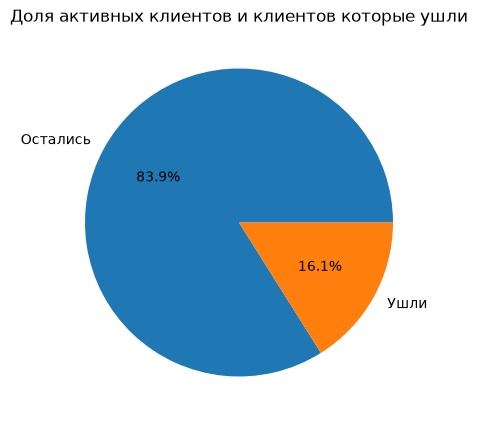

In [56]:
churn_count = df['churn'].value_counts()

fig, ax = plt.subplots(figsize = (8, 5))

ax.pie(churn_count, labels=['Остались', 'Ушли'], autopct = '%1.1f%%')
ax.set_title('Доля активных клиентов и клиентов которые ушли')


*На графике видим, что чуть больше 16% клиентов отказались пользоваться нашими услугами, причины пока не ясны, но учитываюя предыудущий анализ данных можно сделать вывод, что перед тем как клиент уйдет, он будет обращаться в банк*

Text(0.5, 0, 'Оставшиеся и ушедщие клиенту ')

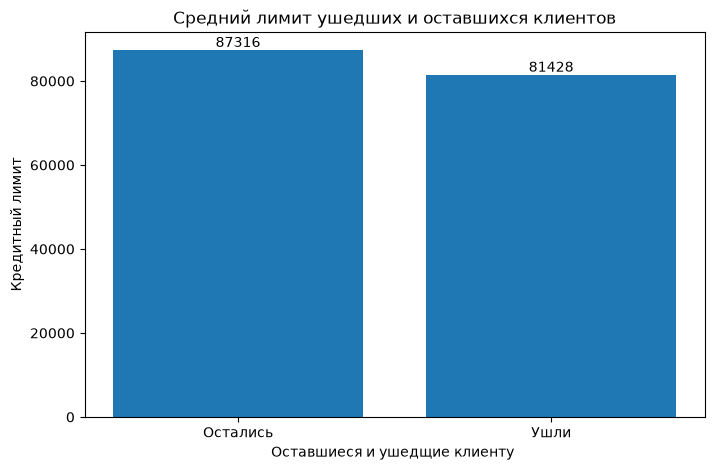

In [57]:
churn_credit_lim = df.groupby('churn')['credit_limit'].mean()

fix, ax = plt.subplots(figsize = (8, 5))
bar = ax.bar(['Остались', 'Ушли'], churn_credit_lim.values)
ax.bar_label(bar, fmt= '%.0f')
ax.set_title('Средний лимит ушедших и оставшихся клиентов')
ax.set_ylabel('Кредитный лимит')
ax.set_xlabel('Оставшиеся и ушедщие клиенту ')

*Можно заметить что у клиентов кто покинул банк, кредитный лимит в среднем меньше чем у тех кто пользуется банком, но он не сушественный*

In [58]:
df['gender'].unique()

<StringArray>
['M', 'F']
Length: 2, dtype: str

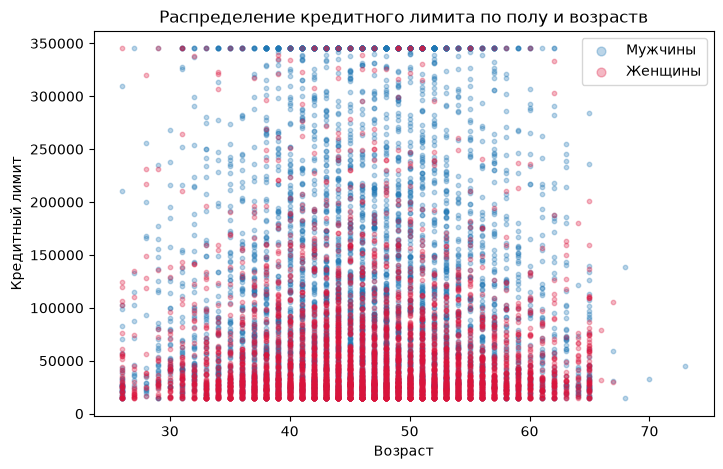

In [59]:
women = df[df['gender'] == 'F']
men = df[df['gender'] == 'M']

fig, ax = plt.subplots(figsize = (8, 5))

ax.scatter(men['age'], men['credit_limit'], s = 10, label = 'Мужчины', alpha= 0.3)
ax.scatter(women['age'], women['credit_limit'], s = 10, color='crimson', alpha= 0.3, label = 'Женщины')

ax.set_title('Распределение кредитного лимита по полу и возраств')
ax.set_xlabel('Возраст')
ax.set_ylabel('Кредитный лимит')
ax.legend(markerscale = 2)

*Связи между возрастом и кредитным лимитом не видно: облако точек не наклонено ни вверх, ни вниз (коэффициент корреляции близок к нулю). Зато заметна разница по полу: у женщин лимиты в основном низкие, а у мужчин встречаются значительно более высокие*

Text(0, 0.5, 'Сумма операций')

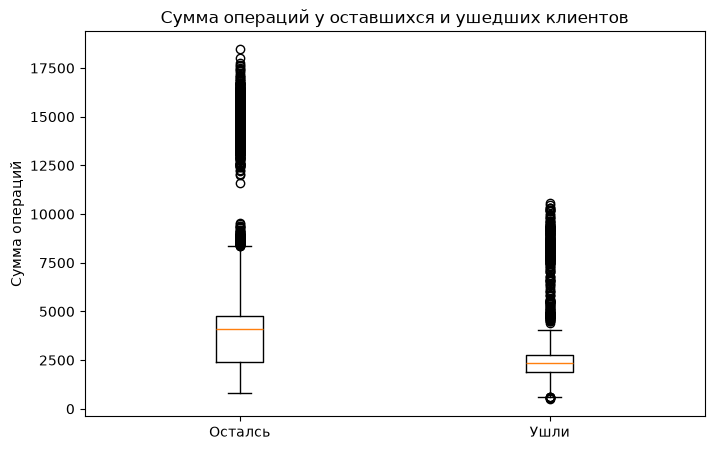

In [60]:
stay = df.loc[df['churn'] == 0, 'total_transactions']
left = df.loc[df['churn'] == 1, 'total_transactions']

fig, ax = plt.subplots(figsize = (8, 5))

ax.boxplot([stay, left], tick_labels=['Осталсь', 'Ушли'])
ax.set_title('Сумма операций у оставшихся и ушедших клиентов')
ax.set_ylabel('Сумма операций')

In [61]:
df.groupby('churn')['total_transactions'].median()

churn
0    4100.0
1    2329.0
Name: total_transactions, dtype: float64

*Медиана оставшихся клиентов составляет 4100, а у тех кто ушли 2329*

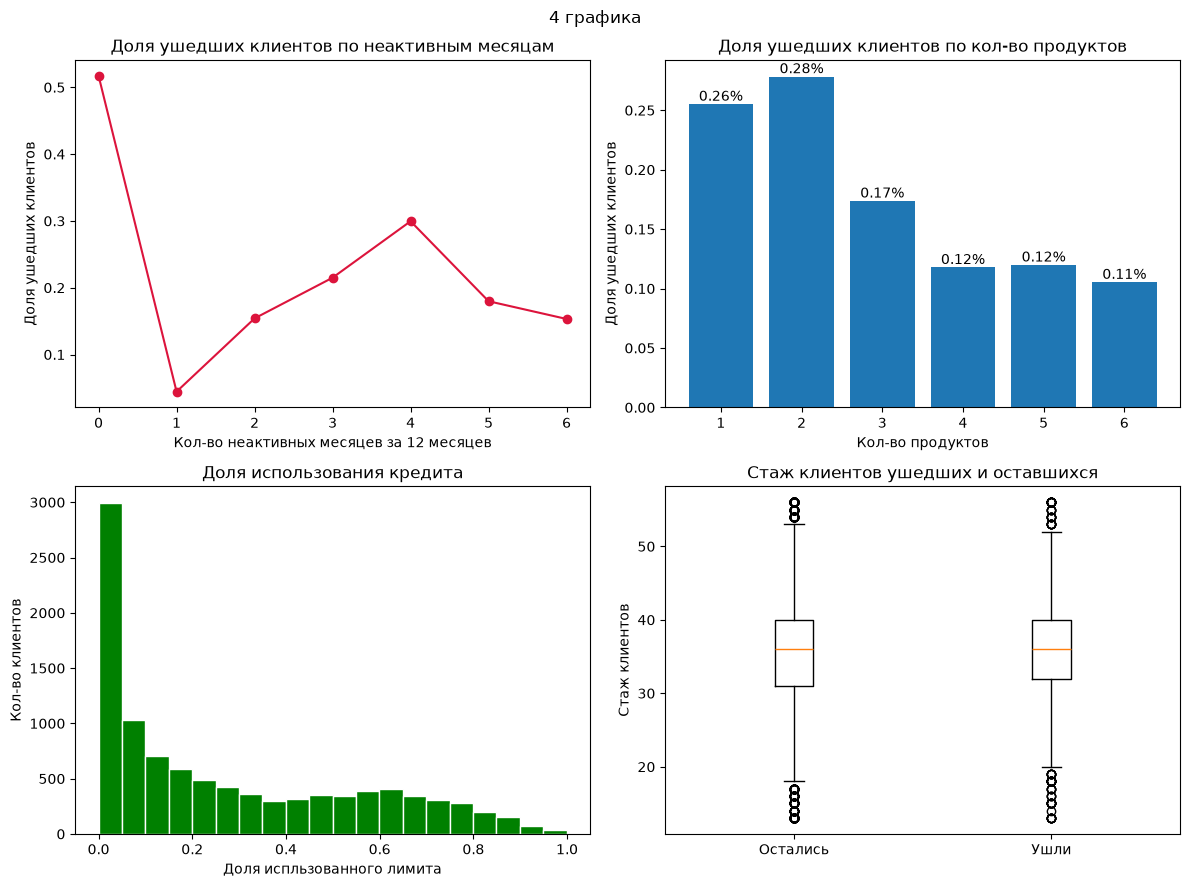

In [71]:
group_inactive = df.groupby('m_inactive_12')['churn'].mean()

fig, ax = plt.subplots(2, 2, figsize = (12, 9))
fig.suptitle('4 графика')

ax[0, 0].plot(group_inactive.index, group_inactive.values, marker = "o", color = 'crimson')
ax[0, 0].set_title('Доля ушедших клиентов по неактивным месяцам')
ax[0, 0].set_xlabel('Кол-во неактивных месяцев за 12 месяцев')
ax[0, 0].set_ylabel('Доля ушедших клиентов')

group_total_prod = df.groupby('total_products')['churn'].mean()
bars = ax[0, 1].bar(group_total_prod.index, group_total_prod.values)
ax[0, 1].bar_label(bars, fmt='%1.2f%%')
ax[0, 1].set_title('Доля ушедших клиентов по кол-во продуктов')
ax[0, 1].set_xlabel('Кол-во продуктов')
ax[0, 1].set_ylabel('Доля ушедших клиентов')

ax[1, 0].hist(df['avg_utilization_ratio'], bins = 20, color = 'green', edgecolor = 'w')
ax[1, 0].set_title('Доля использования кредита')
ax[1, 0].set_xlabel('Доля испльзованного лимита')
ax[1, 0].set_ylabel('Кол-во клиентов')

stay = df.loc[df['churn'] == 0, 'month_client']
left = df.loc[df['churn'] == 1, 'month_client']

ax[1, 1].boxplot([stay, left], tick_labels = ['Остались', 'Ушли'])
ax[1, 1].set_title('Стаж клиентов ушедших и оставшихся')
ax[1, 1].set_ylabel('Стаж клиентов')

fig.tight_layout()
fig.savefig('4_ansver.png', bbox_inches = 'tight' 

In [63]:
group = df.groupby('m_inactive_12')['churn'].mean()

In [64]:
group_total_prod = df.groupby('total_products')['churn'].mean()
group_total_prod

total_products
1    0.255226
2    0.278359
3    0.173762
4    0.117863
5    0.119958
6    0.105376
Name: churn, dtype: float64